# Week 1 — Elephant GPS raw-data audit and engineering contract

**Goal:** Verify the reduced workbook without altering it, record the supported
input/output contract, and document data provenance and responsible use.

**Rule:** Candidate gaps and spatial spikes are flagged for later decisions.
No raw record is deleted in this notebook.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display


current_folder = Path.cwd().resolve()

if (current_folder / "data" / "raw").exists():
    PROJECT_FOLDER = current_folder
elif (current_folder.parent / "data" / "raw").exists():
    PROJECT_FOLDER = current_folder.parent
else:
    raise FileNotFoundError(
        "Python cannot find data/raw. Open the complete MMA3001_project folder "
        "and keep this notebook inside notebooks."
    )

RAW_FOLDER = PROJECT_FOLDER / "data" / "raw"
PROCESSED_FOLDER = PROJECT_FOLDER / "data" / "processed"
FIGURES_FOLDER = PROJECT_FOLDER / "figures"
PRIVATE_FIGURES_FOLDER = FIGURES_FOLDER / "private"
REPORTS_FOLDER = PROJECT_FOLDER / "reports"
SRC_FOLDER = PROJECT_FOLDER / "src"

for folder in [PROCESSED_FOLDER, FIGURES_FOLDER, PRIVATE_FIGURES_FOLDER, REPORTS_FOLDER]:
    folder.mkdir(parents=True, exist_ok=True)

if str(SRC_FOLDER) not in sys.path:
    sys.path.insert(0, str(SRC_FOLDER))

from data_audit import audit_workbook

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

print("Project folder:", PROJECT_FOLDER)
print("Raw folder:", RAW_FOLDER)
print("Python executable:", sys.executable)

Project folder: C:\Users\kookie\OneDrive\MMA3001_project
Raw folder: C:\Users\kookie\OneDrive\MMA3001_project\data\raw
Python executable: c:\Users\kookie\AppData\Local\Python\pythoncore-3.14-64\python.exe


In [2]:
results = audit_workbook(PROJECT_FOLDER)

print("Workbook:", results["workbook_path"])
print("Audit complete.")

Workbook: C:\Users\kookie\OneDrive\MMA3001_project\data\raw\Elephant_GPS_Reduced_60000.xlsx
Audit complete.


In [3]:
display(results["file_inventory"])

,file_name,extension,size_bytes,size_mb
0,Elephant_GPS_Reduced_60000.xlsx,.xlsx,2485430,2.37


In [4]:
print("Sheet order:", results["sheet_names"])
display(results["sheet_inventory"])

Sheet order: ['GPS_Data', 'README', 'Sample_Summary', 'Data_Dictionary']


,sheet_name,rows_read_by_pandas,columns_read_by_pandas
0,GPS_Data,60000,9
1,README,22,8
2,Sample_Summary,18,16
3,Data_Dictionary,12,4


In [5]:
gps_raw = results["gps_raw"]

print("Shape:", gps_raw.shape)
print("\nColumn names:")
print(gps_raw.columns.tolist())
print("\nPandas data types:")
display(gps_raw.dtypes.rename("dtype").to_frame())
print("\nFirst five rows:")
display(gps_raw.head())

Shape: (60000, 9)

Column names:
['AnimalID', 'Species', 'Timestamp', 'Year', 'DayOfYear', 'Latitude', 'Longitude', 'HDOP', 'RecordsCombined']

Pandas data types:


,dtype
AnimalID,str
Species,str
Timestamp,str
Year,int64
DayOfYear,float64
Latitude,float64
Longitude,float64
HDOP,float64
RecordsCombined,int64



First five rows:


,AnimalID,Species,Timestamp,Year,DayOfYear,Latitude,Longitude,HDOP,RecordsCombined
0,LOAF-18-f-2981-1,elephant,2019-05-18 11:46:00,2019,138.0,-18.96542,34.52739,0.0,1
1,LOAF-18-f-2981-1,elephant,2019-05-18 12:00:00,2019,138.0,-18.96591,34.52785,0.0,1
2,LOAF-18-f-2981-1,elephant,2019-05-18 12:15:00,2019,138.0,-18.96638,34.52798,0.0,1
3,LOAF-18-f-2981-1,elephant,2019-05-18 12:30:00,2019,138.0,-18.96686,34.52883,0.0,1
4,LOAF-18-f-2981-1,elephant,2019-05-18 12:45:00,2019,138.0,-18.96772,34.52926,0.0,1


In [6]:
display(results["data_dictionary"])

,field,type,unit_or_format,meaning,project_use
0,AnimalID,text,none,Unique collared-elephant identifier,Group trajectories
1,Species,text,none,Species label; elephant in this subset,Validation/metadata only
2,Timestamp,datetime,"local time, UTC+02:00",Time of GPS fix,Order and downsample trajectories
3,Year,integer,year,Calendar year,Cross-check Timestamp
4,DayOfYear,integer,1-366,Day number within year,Cross-check Timestamp
5,Latitude,number,WGS84 decimal degrees,North/south coordinate,Trajectory reconstruction
6,Longitude,number,WGS84 decimal degrees,East/west coordinate,Trajectory reconstruction
7,HDOP,number,dimensionless,Horizontal dilution of precision,Audit only; constant zero here
8,RecordsCombined,integer,count >= 1,Source rows consolidated into this fix,Cleaning traceability


In [7]:
animal_coverage = results["animal_coverage"]

display(animal_coverage)

print("Number of elephants:", len(animal_coverage))
print("Total GPS rows:", int(animal_coverage["rows"].sum()))

,AnimalID,rows,start_timestamp,end_timestamp,latitude_min,latitude_max,longitude_min,longitude_max,gaps_above_30_minutes,coverage_days
0,LOAF-18-f-2981-1,10000,2019-05-18 11:46:00,2019-08-31 23:00:00,-19.03159,-18.86864,34.40040,34.57314,9,105.47
1,LOAF-18-f-2982-1,10000,2019-05-03 02:18:00,2019-08-16 10:15:00,-19.06878,-18.93288,34.18622,34.34468,7,105.33
2,LOAF-18-f-2983-1,10000,2019-08-22 00:30:00,2019-12-06 01:00:00,-19.12667,-18.88847,34.23984,34.59477,23,106.02
3,LOAF-18-f-2984-1,10000,2018-08-17 01:16:00,2018-11-30 23:00:00,-19.12931,-18.90428,34.28899,34.60529,22,105.91
4,LOAF-18-f-2985-1,10000,2019-08-07 03:16:00,2019-11-20 11:15:00,-19.12729,-18.74630,34.26878,34.60064,3,105.33
5,LOAF-18-f-2986-1,10000,2019-05-30 11:01:00,2019-09-12 23:45:00,-19.06172,-18.92019,34.41712,34.59517,6,105.53


Number of elephants: 6
Total GPS rows: 60000


In [8]:
gps_audit = results["gps_audit"]

domain_summary = pd.DataFrame(
    {
        "item": [
            "earliest_timestamp",
            "latest_timestamp",
            "latitude_min",
            "latitude_max",
            "longitude_min",
            "longitude_max",
        ],
        "value": [
            gps_audit["Timestamp"].min(),
            gps_audit["Timestamp"].max(),
            gps_audit["Latitude"].min(),
            gps_audit["Latitude"].max(),
            gps_audit["Longitude"].min(),
            gps_audit["Longitude"].max(),
        ],
    }
)

display(domain_summary)

,item,value
0,earliest_timestamp,2018-08-17 01:16:00
1,latest_timestamp,2019-12-06 01:00:00
2,latitude_min,-19.12931
3,latitude_max,-18.7463
4,longitude_min,34.18622
5,longitude_max,34.60529


In [9]:
display(results["missingness"])

print(
    "Total missing cells:",
    int(results["missingness"]["missing_count"].sum()),
)

,field,missing_count,missing_percent
0,AnimalID,0,0.0
1,Species,0,0.0
2,Timestamp,0,0.0
3,Year,0,0.0
4,DayOfYear,0,0.0
5,Latitude,0,0.0
6,Longitude,0,0.0
7,HDOP,0,0.0
8,RecordsCombined,0,0.0


Total missing cells: 0


In [10]:
consistency_checks = pd.DataFrame(
    {
        "check": [
            "Duplicate AnimalID + Timestamp rows",
            "Invalid latitude values",
            "Invalid longitude values",
            "Year/Timestamp mismatches",
            "DayOfYear/Timestamp mismatches",
        ],
        "count": [
            results["duplicate_identity_count"],
            results["invalid_latitude_count"],
            results["invalid_longitude_count"],
            results["year_mismatch_count"],
            results["day_of_year_mismatch_count"],
        ],
    }
)

display(consistency_checks)

,check,count
0,Duplicate AnimalID + Timestamp rows,0
1,Invalid latitude values,0
2,Invalid longitude values,0
3,Year/Timestamp mismatches,0
4,DayOfYear/Timestamp mismatches,0


In [11]:
print("Modal positive interval (minutes):", results["modal_gap_minutes"])
print("Median positive interval (minutes):", results["median_gap_minutes"])
print("Maximum interval (minutes):", results["maximum_gap_minutes"])
print("Gaps above 30 minutes:", len(results["long_gaps"]))

Modal positive interval (minutes): 15.0
Median positive interval (minutes): 15.0
Maximum interval (minutes): 91.0
Gaps above 30 minutes: 70


In [12]:
long_gaps = results["long_gaps"]

long_gap_summary = (
    long_gaps.groupby("AnimalID")
    .agg(
        gaps_above_30_minutes=("GapMinutes", "size"),
        largest_gap_minutes=("GapMinutes", "max"),
    )
    .reset_index()
)

display(long_gap_summary)
display(long_gaps.head(20))

,AnimalID,gaps_above_30_minutes,largest_gap_minutes
0,LOAF-18-f-2981-1,9,46.0
1,LOAF-18-f-2982-1,7,46.0
2,LOAF-18-f-2983-1,23,91.0
3,LOAF-18-f-2984-1,22,46.0
4,LOAF-18-f-2985-1,3,45.0
5,LOAF-18-f-2986-1,6,45.0


,AnimalID,Timestamp,GapMinutes,SourceExcelRow
185,LOAF-18-f-2981-1,2019-05-20 10:46:00,31.0,187
4349,LOAF-18-f-2981-1,2019-07-03 09:01:00,31.0,4351
5082,LOAF-18-f-2981-1,2019-07-11 02:31:00,31.0,5084
5811,LOAF-18-f-2981-1,2019-07-18 19:31:00,31.0,5813
6208,LOAF-18-f-2981-1,2019-07-23 00:16:00,31.0,6210
7727,LOAF-18-f-2981-1,2019-08-08 00:16:00,31.0,7729
7822,LOAF-18-f-2981-1,2019-08-09 00:16:00,31.0,7824
8013,LOAF-18-f-2981-1,2019-08-11 00:31:00,46.0,8015
8443,LOAF-18-f-2981-1,2019-08-15 13:46:00,45.0,8445
11182,LOAF-18-f-2982-1,2019-05-15 12:16:00,31.0,11184


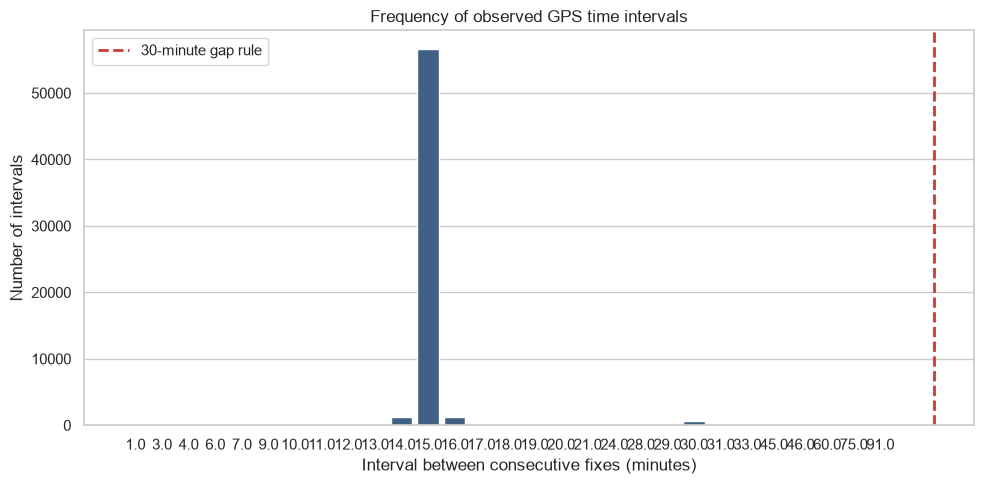

Saved: C:\Users\kookie\OneDrive\MMA3001_project\figures\week1_gap_frequency.png


In [13]:
gap_plot_data = results["gap_frequency"].query("gap_minutes <= 120").copy()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=gap_plot_data,
    x="gap_minutes",
    y="count",
    color="#35618f",
    ax=ax,
)

ax.axvline(30, color="#c43c39", linestyle="--", linewidth=2, label="30-minute gap rule")
ax.set_title("Frequency of observed GPS time intervals")
ax.set_xlabel("Interval between consecutive fixes (minutes)")
ax.set_ylabel("Number of intervals")
ax.legend()
fig.tight_layout()

gap_figure_path = FIGURES_FOLDER / "week1_gap_frequency.png"
fig.savefig(gap_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", gap_figure_path)

In [14]:
candidate_spikes = results["candidate_spikes"]

print("Candidate spatial spikes:", len(candidate_spikes))
display(candidate_spikes)

Candidate spatial spikes: 6


,SourceExcelRow,AnimalID,Timestamp,Latitude,Longitude,GapMinutes,IncomingSpeed_mps,OutgoingSpeed_mps
2453,2455,LOAF-18-f-2981-1,2019-06-13 09:00:00,-18.87116,34.40040,14.0,7.170,6.978
2461,2463,LOAF-18-f-2981-1,2019-06-13 11:00:00,-18.90434,34.48648,15.0,5.355,5.455
2462,2464,LOAF-18-f-2981-1,2019-06-13 11:15:00,-18.86864,34.45902,15.0,5.455,6.343
9810,9812,LOAF-18-f-2981-1,2019-08-29 23:30:00,-18.89923,34.43634,15.0,7.278,7.342
17372,17374,LOAF-18-f-2982-1,2019-07-19 17:45:00,-18.93288,34.32703,15.0,7.033,6.925
55787,55789,LOAF-18-f-2986-1,2019-07-30 14:00:00,-19.06172,34.46960,15.0,14.054,14.191


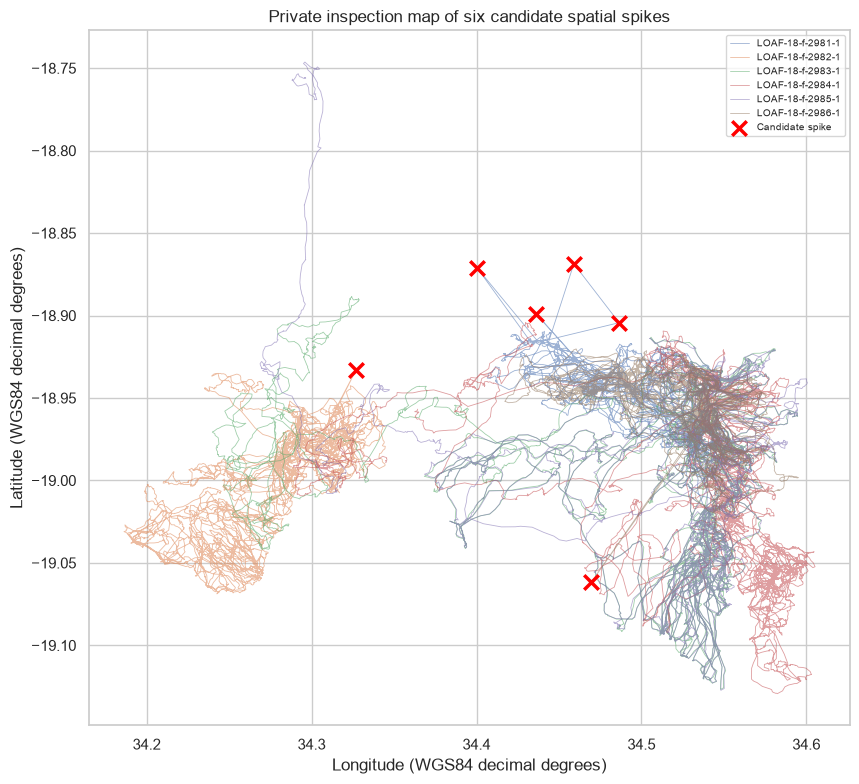

Saved privately: C:\Users\kookie\OneDrive\MMA3001_project\figures\private\week1_candidate_spatial_spikes.png


In [15]:
fig, ax = plt.subplots(figsize=(9, 8))

for animal_id, animal_rows in gps_audit.groupby("AnimalID"):
    ax.plot(
        animal_rows["Longitude"],
        animal_rows["Latitude"],
        linewidth=0.6,
        alpha=0.55,
        label=animal_id,
    )

ax.scatter(
    candidate_spikes["Longitude"],
    candidate_spikes["Latitude"],
    marker="x",
    s=110,
    linewidths=2.5,
    color="red",
    label="Candidate spike",
    zorder=10,
)

ax.set_title("Private inspection map of six candidate spatial spikes")
ax.set_xlabel("Longitude (WGS84 decimal degrees)")
ax.set_ylabel("Latitude (WGS84 decimal degrees)")
ax.legend(fontsize=7, loc="best")
ax.set_aspect("equal", adjustable="box")
fig.tight_layout()

private_spike_figure = PRIVATE_FIGURES_FOLDER / "week1_candidate_spatial_spikes.png"
fig.savefig(private_spike_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Saved privately:", private_spike_figure)

In [16]:
contract_path = REPORTS_FOLDER / "project_contract.md"
display(Markdown(contract_path.read_text(encoding="utf-8")))

# Engineering contract: elephant GPS sampling project

## Engineering question

Which simulated GPS sampling interval minimises the number of collar fixes while
keeping elephant movement-path reconstruction within the provisional accuracy
limits, and how does cubic-spline interpolation compare with linear interpolation?

## Primary inputs

- `AnimalID`: one of the six audited elephant identifiers.
- `Timestamp`: parseable local GPS time (UTC+02:00), ordered within each animal.
- `Latitude`: WGS84 decimal degrees in the audited spatial domain.
- `Longitude`: WGS84 decimal degrees in the audited spatial domain.
- `sampling_interval_minutes`: one of 30, 60, 120, or 240 minutes.
- `method`: linear interpolation baseline or cubic-spline alternative.

`Species`, `Year`, `DayOfYear`, `HDOP`, and `RecordsCombined` are retained for
metadata or audit checks. They are not primary predictors.

## Required outputs

- Reconstructed latitude and longitude at deliberately omitted timestamps.
- Pointwise position error in metres.
- Median, RMSE, and 95th-percentile position error.
- Absolute percentage error in reconstructed total path length.
- Percentage reduction in GPS fixes.
- Runtime for each interval and method.
- Longest interval that passes the approved tolerance.

## Supported domain

- Workbook schema and six AnimalIDs verified by the Week 1 audit.
- Timestamps from 2018-08-17 01:16:00 to 2019-12-06 01:00:00.
- Observed latitude from -19.12931 to -18.74630 degrees.
- Observed longitude from 34.18622 to 34.60529 degrees.
- Coordinate validity: latitude -90 to 90; longitude -180 to 180.
- Tested intervals: 30, 60, 120, and 240 minutes, all multiples of the 15-minute reference interval.
- Interpolation only inside a continuous trajectory segment. Do not interpolate
  across a source gap above 30 minutes and do not extrapolate beyond segment ends.

## Provisional acceptance limits

- Median reconstruction error <= 100 metres.
- Absolute total path-length error <= 10 percent.
- Always report the 95th-percentile error even though it has no initial pass/fail threshold.
- Treat these as initial engineering assumptions and perform sensitivity analysis later.

## Intended engineering use

Compare tracking detail against the number of required GPS fixes so that a
defensible collar sampling schedule can be recommended for these data.

## Unsupported uses and claims

- Do not claim an exact battery-life increase: the workbook has no power/current data.
- Do not claim future movement prediction: this is reconstruction of withheld points.
- Do not claim the 15-minute reference is the elephant's exact continuous path.
- Do not generalise results to every elephant or every location.
- Do not interpolate across long source gaps.
- Do not use HDOP as a quality predictor here because it is constant at zero.


In [17]:
provenance_path = REPORTS_FOLDER / "data_provenance.md"
display(Markdown(provenance_path.read_text(encoding="utf-8")))

# Dataset provenance

## Official source

Hutchinson, Matthew; Walker, Hallie; Abraham, Joel et al. (2026).
*Ecology of community reassembly: Movements and diets of megafauna during a
decade of restoration in Mozambique* [Dataset]. Dryad.
https://doi.org/10.5061/dryad.m905qfv85

Original GPS table: `GPS-COLLAR-LOCATION-RECORDS_ELEPHANT.csv` in `DataS1.zip`.

The official Dryad record reports 839,947 elephant GPS fixes from 18 individuals.
The reduced workbook README reports 839,746 source rows. This 201-row provenance
difference must be recorded rather than silently hidden; it does not alter the
audited 60,000-row reduced workbook.

The official source documents WGS84 decimal-degree coordinates and local GPS
timestamps in UTC+02:00.

## How this reduced workbook was produced

- Six elephants with a nominal 15-minute collar schedule were retained.
- A dense block of 10,000 consecutive fixes was retained per elephant.
- Total reduced size: 60,000 rows.
- The source latitude/longitude fields for the retained LOAF-18 rows were reversed;
  the workbook swapped them to the correct approximately 19 degrees south,
  34 degrees east positions.
- Repeated AnimalID + Timestamp source rows were consolidated with median coordinates.
- `RecordsCombined` records how many source rows were consolidated.
- `DOP` was removed because it was entirely missing.
- `HDOP` was retained for traceability but is constant at zero in this subset.
- Random sampling was not used because it would destroy trajectory order.

## Licence and citation

Dryad publishes datasets under the Creative Commons Zero (CC0) Public Domain
Dedication. Reuse and modification are permitted. The dataset will still be
cited in the report, README, and presentation as scholarly attribution.


In [18]:
data_use_path = REPORTS_FOLDER / "data_use_statement.md"
display(Markdown(data_use_path.read_text(encoding="utf-8")))

# Data-use and location-sensitivity statement

This project uses publicly released historic elephant GPS data from Dryad and
contains no human personal data. CC0 permits reuse; however, exact wildlife
locations can still be sensitive in practice. The exact-coordinate workbook and
all coordinate-bearing processed files will therefore be excluded from the
public GitHub repository. The public repository will contain the DOI, citation,
download/reduction instructions, code, tests, non-sensitive aggregate results,
and documentation. Public maps will be aggregated, rounded, or omitted if exact
locations are unnecessary.


In [19]:
audit_summary = results["audit_summary"]

display(audit_summary)

assert audit_summary["passed"].all(), (
    "At least one Week 1 audit check needs investigation. "
    "Do not continue to Week 2."
)

print("WEEK 1 AUDIT PASSED")

,check,expected,actual,passed,status
0,Required sheet names,"['GPS_Data', 'README', 'Sample_Summary', 'Data...","['GPS_Data', 'README', 'Sample_Summary', 'Data...",True,PASS
1,GPS row count,60000,60000,True,PASS
2,GPS column names,"['AnimalID', 'Species', 'Timestamp', 'Year', '...","['AnimalID', 'Species', 'Timestamp', 'Year', '...",True,PASS
3,Unique AnimalID count,6,6,True,PASS
4,Rows per animal,"10,000 each","[10000, 10000, 10000, 10000, 10000, 10000]",True,PASS
5,Missing cells,0,0,True,PASS
6,Timestamp parse failures,0,0,True,PASS
7,Duplicate AnimalID + Timestamp rows,0,0,True,PASS
8,Invalid latitude values,0,0,True,PASS
9,Invalid longitude values,0,0,True,PASS


WEEK 1 AUDIT PASSED


In [20]:
print("REPORT FILES")
for path in sorted(REPORTS_FOLDER.iterdir()):
    if path.is_file():
        print(" -", path.name)

print("\nPUBLIC FIGURES")
for path in sorted(FIGURES_FOLDER.glob("*.png")):
    print(" -", path.name)

print("\nPRIVATE PROCESSED FILES")
for path in sorted(PROCESSED_FOLDER.iterdir()):
    if path.is_file() and path.name != "README.md":
        print(" -", path.name)

print("\nPRIVATE FIGURES")
for path in sorted(PRIVATE_FIGURES_FOLDER.glob("*.png")):
    print(" -", path.name)

REPORT FILES
 - animal_coverage.csv
 - audit_summary.csv
 - data_dictionary.csv
 - data_provenance.md
 - data_use_statement.md
 - environment_freeze.txt
 - file_inventory.csv
 - gaps_above_30_minutes.csv
 - missingness.csv
 - project_contract.md
 - time_gap_frequency.csv
 - week1_audit.txt
 - workbook_sheets.csv

PUBLIC FIGURES
 - week1_gap_frequency.png

PRIVATE PROCESSED FILES
 - week1_candidate_spatial_spikes.csv

PRIVATE FIGURES
 - week1_candidate_spatial_spikes.png


In [21]:
print("EXTRA TEST: Python is working on this device!")

EXTRA TEST: Python is working on this device!
